In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df["Churn"].value_counts() #There is Class Imbalance

,count
Churn,
No,5174
Yes,1869


In [8]:
(df["Churn"].value_counts()/len(df)) * 100

,count
Churn,
No,73.463013
Yes,26.536987


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce") # Where there will be errors , there NaN value will get filled

In [10]:
#Now fill those NaN values with 0 cause TotalCharges = 0 for new customers , we cannot fill it with mean , median or mode
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [11]:
df.duplicated().sum()

np.int64(0)

## Drop CustomerID

In [12]:
df.drop(columns=["customerID"],inplace=True)

## Encode Churn Column

In [13]:
df["Churn"] = df["Churn"].map({"Yes":1,"No":0})

In [14]:
df["Churn"]

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


# EDA

In [15]:
numerical_cols = df.select_dtypes(include=np.number)
categorical_cols = df.select_dtypes(exclude=np.number)

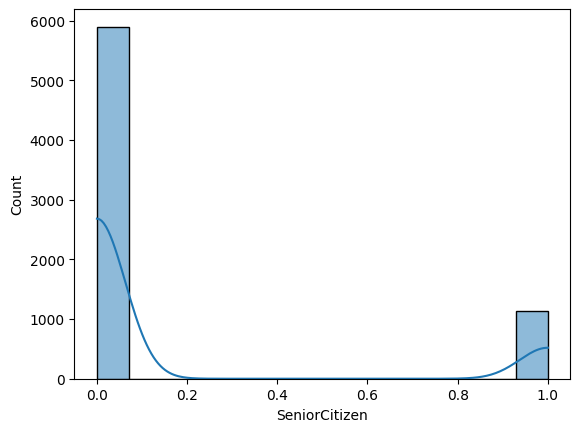

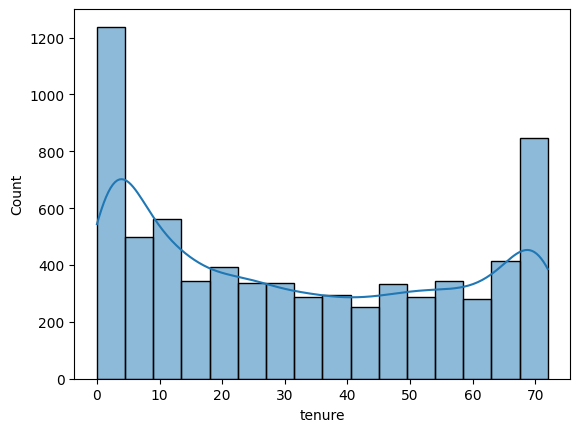

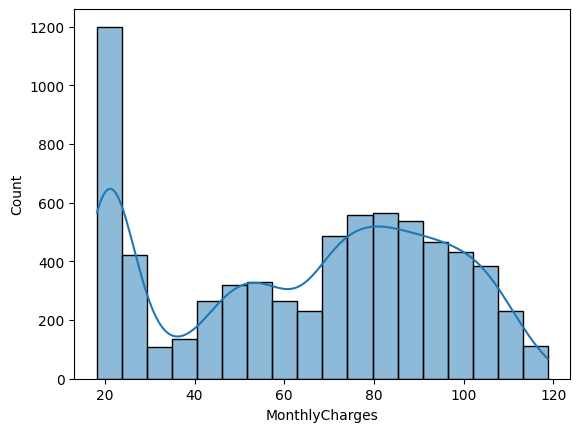

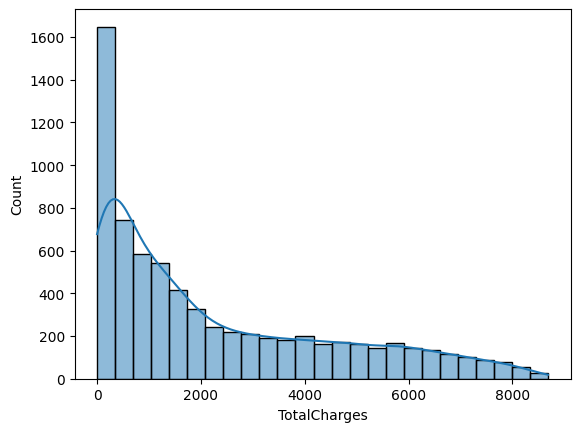

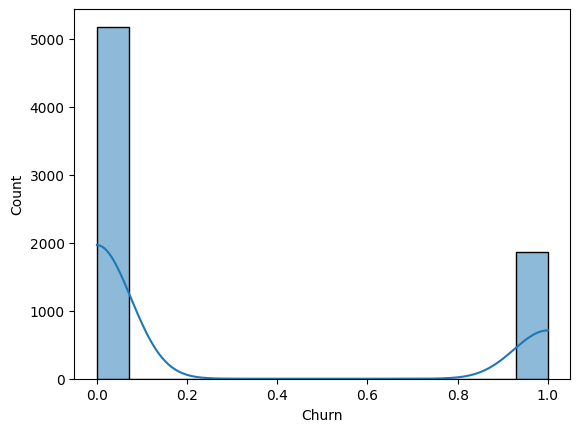

In [16]:
for i in numerical_cols[0:4]: #Excluded Last Column i.e Churn
  sns.histplot(data=df,x=i,kde=True)
  plt.show()

In [17]:
cols = df[["SeniorCitizen","tenure" ,"MonthlyCharges","TotalCharges" ,"Churn"]]
df.groupby("Churn")[cols.columns[1:4]].agg(["mean","median"]) #Columns = tenure , MonthlyCharges , TotalCharges

tenure        MonthlyCharges         TotalCharges          
            mean median           mean  median         mean    median
Churn                                                                
0      37.569965   38.0      61.265124  64.425  2549.911442  1679.525
1      17.979133   10.0      74.441332  79.650  1531.796094   703.550

<Axes: >

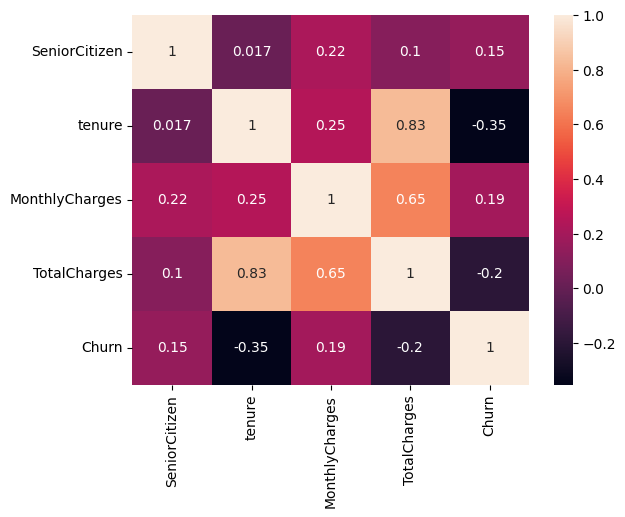

In [18]:
sns.heatmap(numerical_cols.corr(),annot=True)

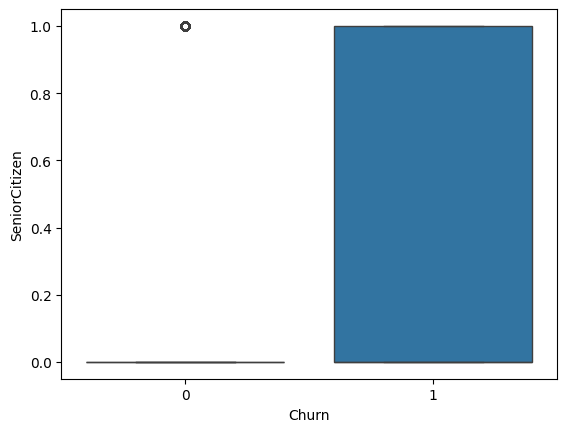

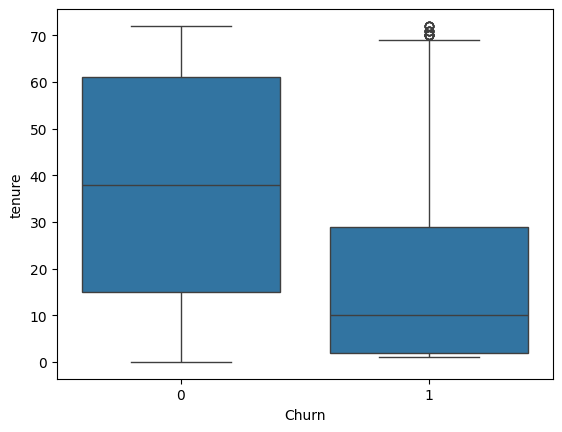

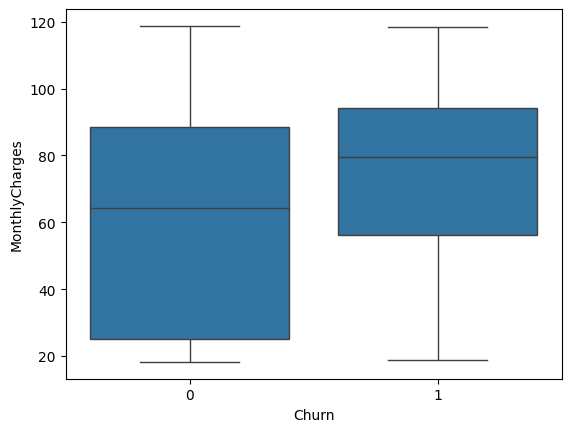

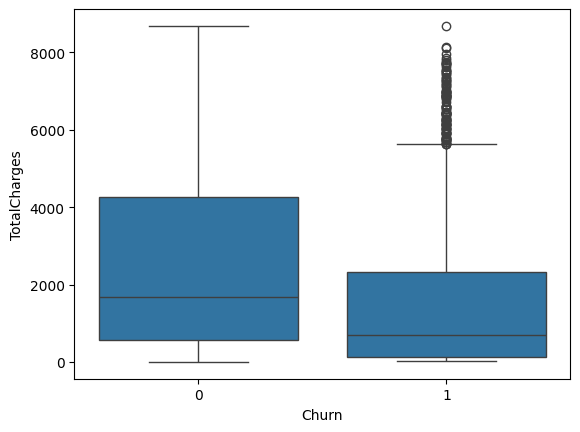

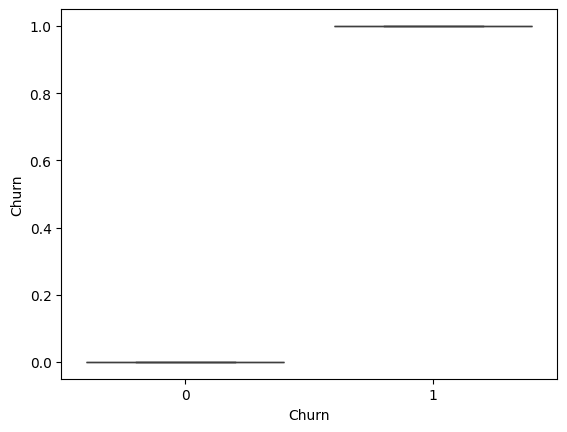

In [19]:
for i in numerical_cols[1:4]:
  sns.boxplot(data=df,x="Churn",y=i)
  plt.show()

<Axes: >

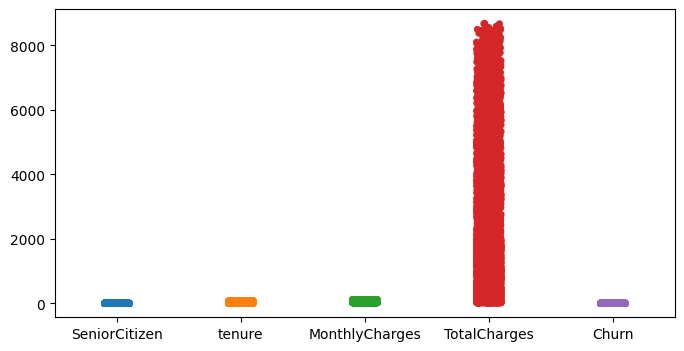

In [20]:
plt.figure(figsize=(8,4))
sns.stripplot(df)

In [21]:
df.groupby("gender")["Churn"].agg("mean") # Churn Rate is not depending on gender type , both are having same average value

,Churn
gender,
Female,0.269209
Male,0.261603


In [22]:
for col in categorical_cols:
  print(f"Churn rate (%) by {col}")
  print((df.groupby(col)["Churn"].agg("mean")*100).round(1))
  print()

Churn rate (%) by gender
gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64

Churn rate (%) by Partner
Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64

Churn rate (%) by Dependents
Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64

Churn rate (%) by PhoneService
PhoneService
No     24.9
Yes    26.7
Name: Churn, dtype: float64

Churn rate (%) by MultipleLines
MultipleLines
No                  25.0
No phone service    24.9
Yes                 28.6
Name: Churn, dtype: float64

Churn rate (%) by InternetService
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64

Churn rate (%) by OnlineSecurity
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn, dtype: float64

Churn rate (%) by OnlineBackup
OnlineBackup
No                     39.9
No internet service     7.4
Yes                    21.5
Name: Churn, dtype: float64

Churn rate (%) by DeviceP

## Inreraction Analysis : Do combinations create Sharper segments ?

In [23]:
pd.crosstab(df["InternetService"] , df["Contract"], values=df["Churn"],aggfunc="mean") * 100
#Fiber Optic have the most Churn Rate in Contract and also in General

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.215863,9.298246,1.910828
Fiber optic,54.605263,19.294991,7.226107
No,18.893130,2.472527,0.783699


In [24]:
pd.crosstab(df["InternetService"] , df["TechSupport"],values=df["Churn"],aggfunc="mean") * 100
#Giving Tech Support will reduce Customers Churn Rate

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,27.755430,NaN,9.677419
Fiber optic,49.372197,NaN,22.632794
No,NaN,7.40498,NaN


In [25]:
# There are negligible or no Outliers in our Data except SeniorCitizen Column but these are actually not Outliers , They are showing frequency of 1

Q1 = numerical_cols.quantile(0.25)
Q3 = numerical_cols.quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

Outliers = (numerical_cols < lower_bound) | (numerical_cols > upper_bound)

Outliers.sum(
)

,0
SeniorCitizen,1142
tenure,0
MonthlyCharges,0
TotalCharges,0
Churn,0


In [26]:
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


# Model Building

## 1) Multicollinearity Check

<Axes: >

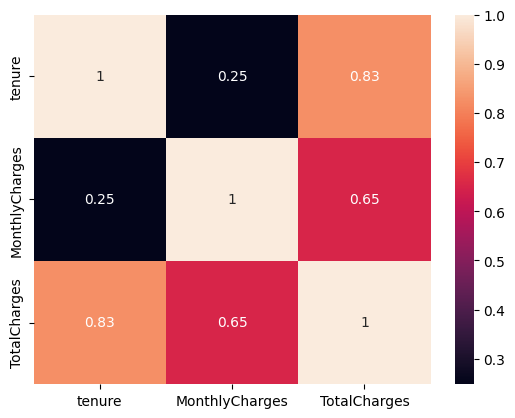

In [27]:
"""Extra checks cause one model is Linear (Logistic Regression)"""

multicollinearity = numerical_cols.drop(columns=["SeniorCitizen", "Churn"])

sns.heatmap(multicollinearity.corr(),annot=True) #Tenure and Total Charges are highly Correlated So going to drop any one --> Droping total_charges cause total_charges can be easily found by tenure * monthly_charges


In [28]:
df = df.drop(columns=["TotalCharges"])

## 2) Train Test Split

In [29]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


## 3) Encoding + Scaling

In [30]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

num_cols = ["tenure", "MonthlyCharges"]
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
# SeniorCitizen is already 0/1, so it passes through untouched

preprocess_lr = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

preprocess_xgb = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ],
    remainder="passthrough",          # numerical cols + SeniorCitizen pass through
    verbose_feature_names_out=False,
)

## 4) Logistic Regression

In [31]:
from sklearn.metrics import accuracy_score ,confusion_matrix, precision_score , recall_score , f1_score

In [32]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("prep", preprocess_lr),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

lr_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['tenure',
                                                   'MonthlyCharges'])],
                                   verbose_feature_names_out=False)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
y_pred = lr_model.predict(X_test)

print(f"Confusion Matrix : \n{confusion_matrix(y_test,y_pred)}")
print(f"Accuracy Score : {accuracy_score(y_test,y_pred)}")
print(f"Precision Score : {precision_score(y_test,y_pred)}")
print(f"Recall Score : {recall_score(y_test,y_pred)}")
print(f"F1 Score : {f1_score(y_test,y_pred)}")

Confusion Matrix : 
[[753 282]
 [ 85 289]]
Accuracy Score : 0.7395315826827538
Precision Score : 0.5061295971978984
Recall Score : 0.7727272727272727
F1 Score : 0.6116402116402117


## 5) RandomForest (class-balanced)

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("prep", preprocess_xgb),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",   # fair comparison: same imbalance handling as LR / XGBoost
        min_samples_leaf=5,                  # limits overfitting on a small dataset
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])],
                                   verbose_feature_names_out=False)),
                ('clf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        min_samples_leaf=5, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [35]:
y_pred = rf_model.predict(X_test)

print(f"Confusion Matrix : \n{confusion_matrix(y_test,y_pred)}")
print(f"Accuracy Score : {accuracy_score(y_test,y_pred)}")
print(f"Precision Score : {precision_score(y_test,y_pred)}")
print(f"Recall Score : {recall_score(y_test,y_pred)}")
print(f"F1 Score : {f1_score(y_test,y_pred)}")

Confusion Matrix : 
[[802 233]
 [101 273]]
Accuracy Score : 0.7629524485450674
Precision Score : 0.5395256916996047
Recall Score : 0.7299465240641712
F1 Score : 0.6204545454545455


## 6) XGBoostClassifier

In [36]:
from xgboost import XGBClassifier

In [37]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 2.77


In [38]:
xgb_model = Pipeline([
    ("prep", preprocess_xgb),
    ("clf", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )),
])

xgb_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBill...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [39]:
y_pred = xgb_model.predict(X_test)

print(f"Confusion Matrix : \n{confusion_matrix(y_test,y_pred)}")
print(f"Accuracy Score : {accuracy_score(y_test,y_pred)}")
print(f"Precision Score : {precision_score(y_test,y_pred)}")
print(f"Recall Score : {recall_score(y_test,y_pred)}")
print(f"F1 Score : {f1_score(y_test,y_pred)}")

Confusion Matrix : 
[[767 268]
 [ 83 291]]
Accuracy Score : 0.7508871540099361
Precision Score : 0.5205724508050089
Recall Score : 0.7780748663101604
F1 Score : 0.6237942122186495


## 7) Fair Model Comparison
All three models now handle class imbalance (`class_weight='balanced'`, `'balanced_subsample'`, `scale_pos_weight`), so the comparison is about the models, not about the imbalance handling.

Accuracy is not used to pick the model: always predicting "No churn" already gives ~73.5%. We use **ROC-AUC** and **PR-AUC** (both threshold-independent).

In [40]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
}

### 7.1) Cross-Validation on Training Data (used for model selection)
Preprocessing is refit inside every fold because the whole Pipeline is passed in, so there is no leakage.

In [41]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, m in models.items():
    scores = cross_validate(
        m, X_train, y_train, cv=skf,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
        n_jobs=1,
    )
    cv_rows[name] = {
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV ROC-AUC std": scores["test_roc_auc"].std(),
        "CV PR-AUC": scores["test_pr_auc"].mean(),
        "CV PR-AUC std": scores["test_pr_auc"].std(),
    }

cv_results = pd.DataFrame(cv_rows).T.round(4)
cv_results

,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,CV PR-AUC std
Logistic Regression,0.8447,0.0121,0.6586,0.0187
Random Forest,0.8427,0.0076,0.6444,0.0191
XGBoost,0.8433,0.0102,0.6651,0.0170


### 7.2) Test Set Metrics (threshold-independent + default 0.5 threshold)

In [42]:
test_rows = {}
test_proba = {}
test_pred = {}

for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    pred = m.predict(X_test)                      # default threshold = 0.5
    test_proba[name], test_pred[name] = proba, pred
    test_rows[name] = {
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Recall (churn)": recall_score(y_test, pred),
        "Precision (churn)": precision_score(y_test, pred),
        "F1 (churn)": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    }

test_results = pd.DataFrame(test_rows).T.round(4)
test_results

,Test ROC-AUC,Test PR-AUC,Recall (churn),Precision (churn),F1 (churn),Accuracy
Logistic Regression,0.8387,0.6285,0.7727,0.5061,0.6116,0.7395
Random Forest,0.8377,0.6417,0.7299,0.5395,0.6205,0.7630
XGBoost,0.8402,0.6509,0.7781,0.5206,0.6238,0.7509


### 7.3) Final Comparison Table (all models, one view)

In [43]:
comparison = cv_results[["CV ROC-AUC", "CV PR-AUC"]].join(test_results)
comparison.sort_values("CV ROC-AUC", ascending=False)

,CV ROC-AUC,CV PR-AUC,Test ROC-AUC,Test PR-AUC,Recall (churn),Precision (churn),F1 (churn),Accuracy
Logistic Regression,0.8447,0.6586,0.8387,0.6285,0.7727,0.5061,0.6116,0.7395
XGBoost,0.8433,0.6651,0.8402,0.6509,0.7781,0.5206,0.6238,0.7509
Random Forest,0.8427,0.6444,0.8377,0.6417,0.7299,0.5395,0.6205,0.7630


### 7.4) ROC and Precision-Recall Curves

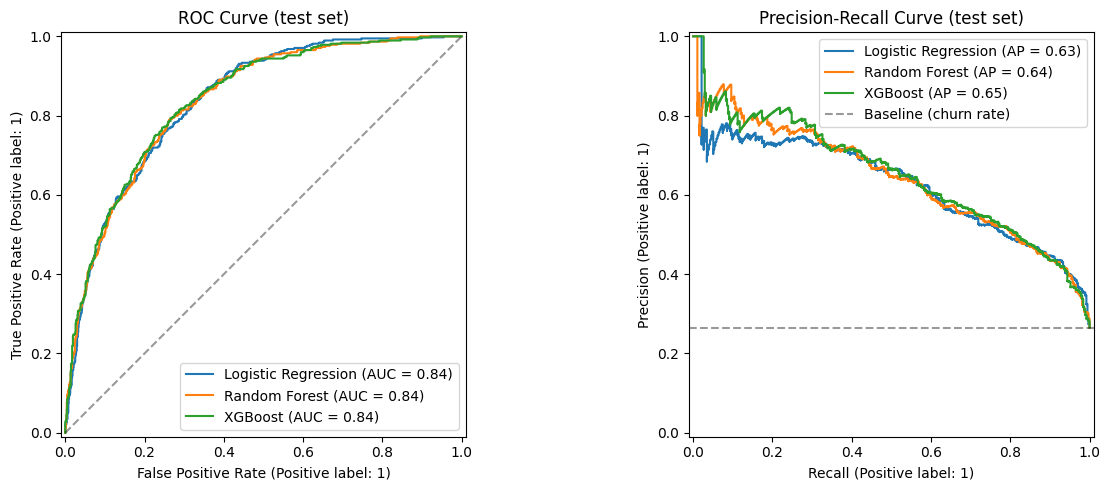

In [44]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name in models:
    RocCurveDisplay.from_predictions(y_test, test_proba[name], name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, test_proba[name], name=name, ax=ax[1])

ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_title("ROC Curve (test set)")
ax[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="Baseline (churn rate)")
ax[1].set_title("Precision-Recall Curve (test set)")
ax[1].legend()
plt.tight_layout()
plt.show()

## 8) Pick the Final Model
The model is chosen on **cross-validation ROC-AUC (training data only)**, not on the test set. If two models are within about 0.005 AUC, prefer the simpler / more interpretable one (Logistic Regression).

In [45]:
final_name = "Logistic Regression"      # locked: chosen on CV ROC-AUC + interpretability
final_model = models[final_name]
print("Final model:", final_name)
cv_results.sort_values("CV ROC-AUC", ascending=False)

Final model: Logistic Regression


,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,CV PR-AUC std
Logistic Regression,0.8447,0.0121,0.6586,0.0187
XGBoost,0.8433,0.0102,0.6651,0.0170
Random Forest,0.8427,0.0076,0.6444,0.0191


## 9) Decision Threshold Tuning (business-driven)
The default 0.5 threshold is arbitrary. We choose the threshold using **out-of-fold predictions on the training set**, so the test set stays untouched until the final check.

**Business assumptions (edit these to match your telecom case):**
- `offer_cost`: cost of sending a retention offer to one customer
- `customer_value`: revenue lost when a customer churns
- `retention_success`: share of contacted churners the offer actually saves

In [46]:
from sklearn.model_selection import cross_val_predict

offer_cost = 20          # cost of one retention offer
customer_value = 300     # value lost if a customer churns
retention_success = 0.5  # fraction of contacted churners we manage to keep

# Out-of-fold churn probabilities on TRAIN only
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

def total_cost(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    contacted = tp + fp
    saved = tp * retention_success
    missed = fn + tp * (1 - retention_success)       # churners that still leave
    return contacted * offer_cost + missed * customer_value

thresholds = np.arange(0.05, 0.96, 0.01)
costs = np.array([total_cost(y_train, oof_proba, t) for t in thresholds])
best_threshold = float(thresholds[costs.argmin()])
print(f"Best threshold (min expected cost on train OOF): {best_threshold:.2f}")

Best threshold (min expected cost on train OOF): 0.29


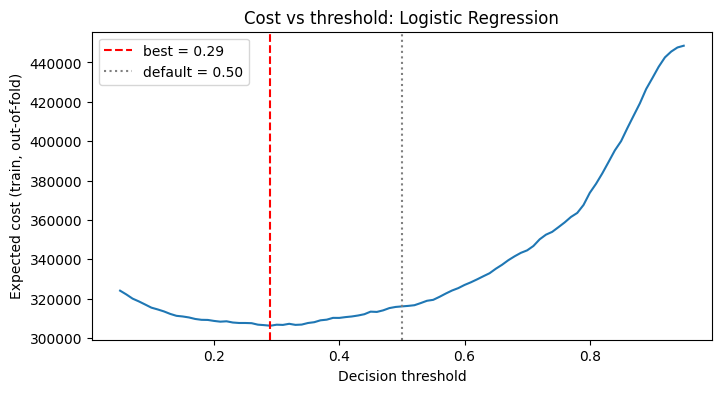

In [47]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="r", linestyle="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="gray", linestyle=":", label="default = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel("Expected cost (train, out-of-fold)")
plt.title(f"Cost vs threshold: {final_name}")
plt.legend()
plt.show()

### 9.1) Final Evaluation on Test Set: default 0.5 vs tuned threshold
This is the only time the test set is used for the final decision.

In [48]:
final_proba = final_model.predict_proba(X_test)[:, 1]

rows = {}
for label, t in [("Default (0.50)", 0.5), (f"Tuned ({best_threshold:.2f})", best_threshold)]:
    pred = (final_proba >= t).astype(int)
    rows[label] = {
        "Recall (churn)": recall_score(y_test, pred),
        "Precision (churn)": precision_score(y_test, pred),
        "F1 (churn)": f1_score(y_test, pred),
        "Expected cost (test)": total_cost(y_test, final_proba, t),
    }

print(f"Model: {final_name} | Test ROC-AUC: {roc_auc_score(y_test, final_proba):.4f} | Test PR-AUC: {average_precision_score(y_test, final_proba):.4f}")
pd.DataFrame(rows).T.round(3)

Model: Logistic Regression | Test ROC-AUC: 0.8387 | Test PR-AUC: 0.6285


,Recall (churn),Precision (churn),F1 (churn),Expected cost (test)
Default (0.50),0.773,0.506,0.612,80270.0
Tuned (0.29),0.933,0.425,0.584,76270.0


In [49]:
tuned_pred = (final_proba >= best_threshold).astype(int)
print(f"Confusion Matrix at threshold {best_threshold:.2f}:")
print(confusion_matrix(y_test, tuned_pred))

Confusion Matrix at threshold 0.29:
[[563 472]
 [ 25 349]]


## 10) Churn Drivers (Odds Ratios)
Numerical features are standardized, so their odds ratios are per 1 standard deviation. For one-hot columns, the comparison is against the dropped reference category. An odds ratio above 1 raises churn odds, and below 1 lowers them.

In [50]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
coefs = final_model.named_steps["clf"].coef_[0]

odds = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs),
}).sort_values("coefficient", key=abs, ascending=False)

odds.head(10).round(3)

,feature,coefficient,odds_ratio
21,Contract_Two year,-1.407,0.245
6,InternetService_Fiber optic,1.247,3.479
26,tenure,-0.757,0.469
20,Contract_One year,-0.724,0.485
19,StreamingMovies_Yes,0.445,1.560
27,MonthlyCharges,-0.423,0.655
17,StreamingTV_Yes,0.422,1.524
24,PaymentMethod_Electronic check,0.399,1.491
5,MultipleLines_Yes,0.349,1.418
3,PhoneService_Yes,-0.339,0.713


## 11) Save the Final Model with its Threshold

In [51]:
import joblib

artifact = {
    "pipeline": final_model,
    "threshold": float(best_threshold),
    "model_name": final_name,
}
joblib.dump(artifact, "churn_lr_pipeline.joblib")


def predict_churn(df_new, artifact=artifact):
    """Applies the saved threshold. Input needs the same columns as X_train."""
    proba = artifact["pipeline"].predict_proba(df_new)[:, 1]
    return pd.DataFrame({
        "churn_probability": proba.round(3),
        "churn_flag": (proba >= artifact["threshold"]).astype(int),
    }, index=df_new.index)


predict_churn(X_test.head())

,churn_probability,churn_flag
437,0.088,0
2280,0.866,1
2235,0.157,0
4460,0.666,1
3761,0.063,0
